In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report


In [3]:
df = pd.read_csv("../output/features/merged_results.csv")
df.drop(columns=["coordinateUncertaintyInMeters", "gbifID"], inplace=True)
df.dropna(inplace=True)

In [4]:
species_counts = df["species"].value_counts()
species_to_keep = species_counts[(species_counts > 100) & (species_counts < 1500)].index
df = df[df["species"].isin(species_to_keep)]
print(df.shape)
df["species"].value_counts()

(8556, 29)


species
Armeria alpina              1054
Sibbaldia procumbens         975
Carex myosuroides            843
Carex parviflora             822
Petrocallis pyrenaica        673
Astragalus alpinus           630
Kalmia procumbens            544
Erigeron alpinus             534
Juncus triglumis             454
Comastoma tenellum           434
Draba dubia                  400
Astragalus penduliflorus     324
Carex rupestris              273
Gentiana orbicularis         254
Coronilla vaginalis          201
Arctostaphylos alpinus       141
Name: count, dtype: int64

In [5]:
cords_df = df[["species", "decimalLatitude", "decimalLongitude"]]
df = df.drop(columns=["decimalLatitude", "decimalLongitude"])
print(df.shape)
df.columns

(8556, 27)


Index(['species', 'elevation', 'slope', 'aspect', 'TPI', 'TRI', 'roughness',
       'flowdir', 'wc2.1_30s_bio_1', 'wc2.1_30s_bio_10', 'wc2.1_30s_bio_11',
       'wc2.1_30s_bio_12', 'wc2.1_30s_bio_13', 'wc2.1_30s_bio_14',
       'wc2.1_30s_bio_15', 'wc2.1_30s_bio_16', 'wc2.1_30s_bio_17',
       'wc2.1_30s_bio_18', 'wc2.1_30s_bio_19', 'wc2.1_30s_bio_2',
       'wc2.1_30s_bio_3', 'wc2.1_30s_bio_4', 'wc2.1_30s_bio_5',
       'wc2.1_30s_bio_6', 'wc2.1_30s_bio_7', 'wc2.1_30s_bio_8',
       'wc2.1_30s_bio_9'],
      dtype='str')

In [6]:
species_map = {species: idx for idx, species in enumerate(df["species"].unique())}
species_map

{'Comastoma tenellum': 0,
 'Arctostaphylos alpinus': 1,
 'Draba dubia': 2,
 'Carex myosuroides': 3,
 'Armeria alpina': 4,
 'Erigeron alpinus': 5,
 'Astragalus alpinus': 6,
 'Coronilla vaginalis': 7,
 'Kalmia procumbens': 8,
 'Astragalus penduliflorus': 9,
 'Juncus triglumis': 10,
 'Carex rupestris': 11,
 'Carex parviflora': 12,
 'Petrocallis pyrenaica': 13,
 'Sibbaldia procumbens': 14,
 'Gentiana orbicularis': 15}

In [7]:
df["species"] = df["species"].map(species_map)
print(df["species"].unique())

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]


In [8]:
X = df.drop(columns=["species"])
y = df["species"]

(array([ 434.,  141.,  400.,  843., 1054.,  534.,  630.,  201.,  544.,
         324.,  454.,  273.,  822.,  673.,  975.,  254.]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5,
        10.5, 11.5, 12.5, 13.5, 14.5, 15.5]),
 <BarContainer object of 16 artists>)

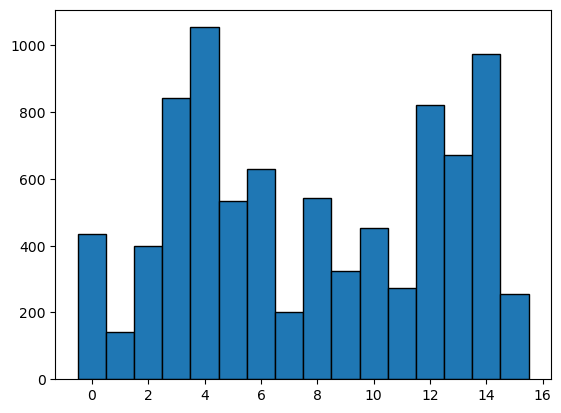

In [9]:
plt.hist(y, bins=np.arange(len(species_map) + 1) - 0.5, edgecolor="black")

In [10]:
scalaer = StandardScaler()
X_scaled = scalaer.fit_transform(X)
print(X_scaled.shape)

(8556, 26)


In [11]:
pca = PCA(n_components=20)
X_pca = pca.fit_transform(X_scaled)

Explained variance: [3.11948406e-01 2.18202355e-01 1.47570781e-01 1.11387874e-01
 5.07792585e-02 4.73558622e-02 3.37350427e-02 2.94314805e-02
 2.76745962e-02 9.55691635e-03 2.70947558e-03 2.45521956e-03
 1.92455999e-03 1.50038431e-03 1.24939763e-03 8.15220804e-04
 5.69251408e-04 4.66694797e-04 2.46759097e-04 1.96855516e-04]
Cumulative: [0.31194841 0.53015076 0.67772154 0.78910942 0.83988867 0.88724454
 0.92097958 0.95041106 0.97808566 0.98764257 0.99035205 0.99280727
 0.99473183 0.99623221 0.99748161 0.99829683 0.99886608 0.99933278
 0.99957954 0.99977639]


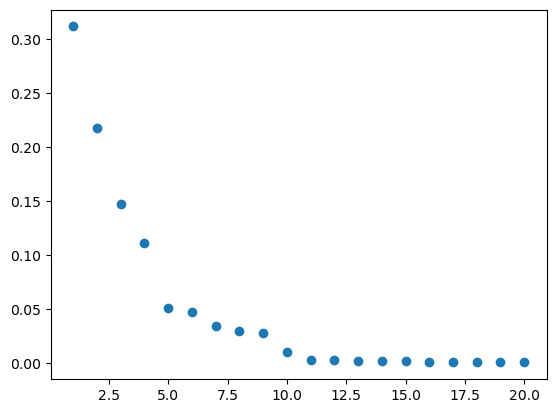

In [12]:
print("Explained variance:", pca.explained_variance_ratio_)
print("Cumulative:", np.cumsum(pca.explained_variance_ratio_))
plt.scatter(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, marker="o")

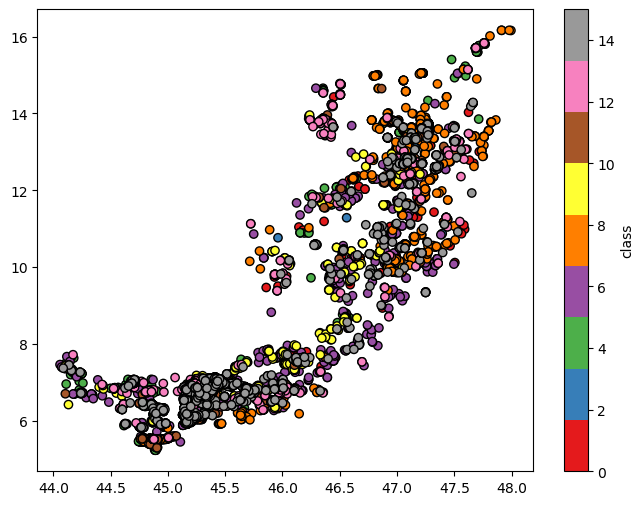

In [13]:
plt.figure(figsize=(8,6))
plt.scatter(cords_df.decimalLatitude, cords_df.decimalLongitude, c=y, cmap='Set1', edgecolor='k')
plt.colorbar(label="class")
plt.show()

Zrobię takie kwadraciki 2 wymiarowe z (x, y). Żeby jakoś te stanowiska pogrupować. I później pewnie każde stanowisko sobie przedstawię jako binarny wektor 16 wymiarowy (liczba gatunków).
Te gridy są trochę mało "geograficzne". Pewnie lepiej pogrupować te stanowiska jakimś dbscan po lokalizacji.

Wtedy będziemy mieć mniej rekordów. I będziemy na ich podstawie przewidywać 16 wartości 1/0.

Klastrujemy bez normalizacji, bo równoleżnik południkowi nie równy i to dobrze, ale użyję metryki Haversina (przy tym naszym na modmolu tak robiłem też).

In [14]:
res = 0.05 # 100 metrów chyba
cords_df["lat_bin"] = (cords_df["decimalLatitude"] // res)
cords_df["lon_bin"] = (cords_df["decimalLongitude"] // res)
cords_df["grid_cell"] = cords_df["lat_bin"].astype(str) + "_" + cords_df["lon_bin"].astype(str)
cords_df.head()

,species,decimalLatitude,decimalLongitude,lat_bin,lon_bin,grid_cell
3548,Comastoma tenellum,45.415268,7.028685,908.0,140.0,908.0_140.0
3549,Comastoma tenellum,47.120875,12.820054,942.0,256.0,942.0_256.0
3550,Comastoma tenellum,47.159256,13.382659,943.0,267.0,943.0_267.0
3551,Comastoma tenellum,47.057584,12.858508,941.0,257.0,941.0_257.0
3552,Comastoma tenellum,47.120875,12.820054,942.0,256.0,942.0_256.0


In [15]:
grid_species_counts = cords_df.groupby(["grid_cell", "species"]).size().unstack(fill_value=0)
grid_species_counts = (grid_species_counts > 0).astype(int)
print(grid_species_counts.shape)
grid_species_counts.head()

(1141, 16)


species,Arctostaphylos alpinus,Armeria alpina,Astragalus alpinus,Astragalus penduliflorus,Carex myosuroides,Carex parviflora,Carex rupestris,Comastoma tenellum,Coronilla vaginalis,Draba dubia,Erigeron alpinus,Gentiana orbicularis,Juncus triglumis,Kalmia procumbens,Petrocallis pyrenaica,Sibbaldia procumbens
grid_cell,,,,,,,,,,,,,,,,
881.0_147.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
881.0_148.0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0
881.0_149.0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
882.0_128.0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
882.0_134.0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


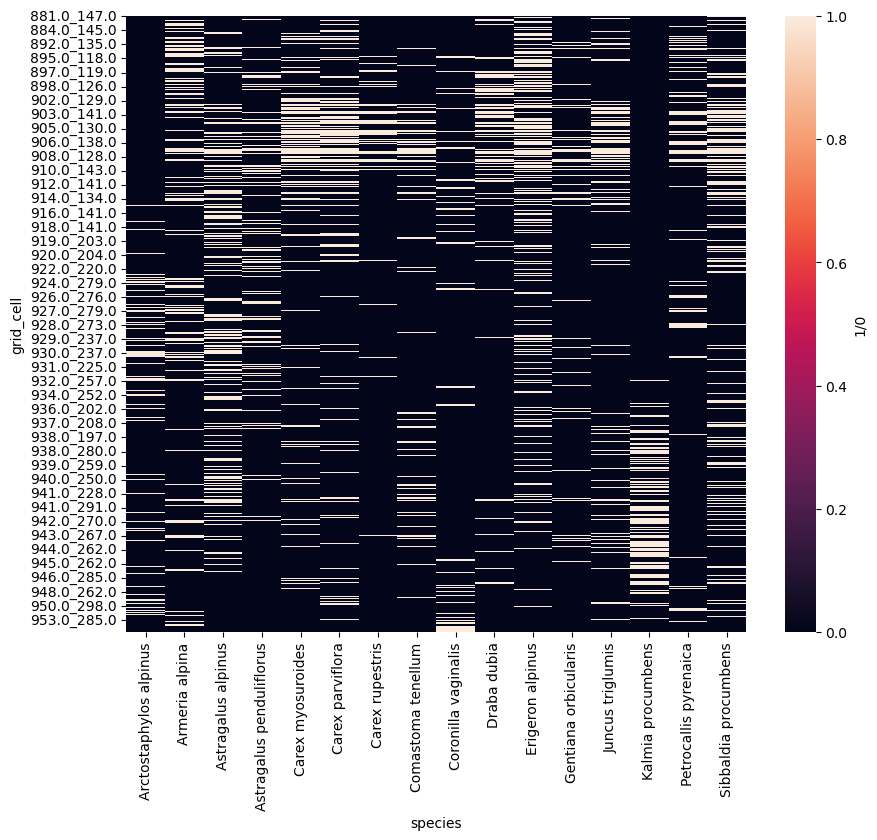

In [16]:
plt.figure(figsize=(10,8))
sns.heatmap(grid_species_counts, cbar_kws={'label': '1/0'})
plt.show()

tutaj tak po prostu naiwnie w krateczkę. Poniżej dbscan

In [17]:
from sklearn.cluster import DBSCAN
import numpy as np

coords_rad = np.radians(cords_df[["decimalLatitude", "decimalLongitude"]].values)

epsilon_km = 0.5
db = DBSCAN(
    eps=epsilon_km / 6371.0,
    min_samples=1,
    algorithm='ball_tree',
    metric='haversine'
)
cords_df["site"] = db.fit_predict(coords_rad)

print(f"Liczba stanowisk: {cords_df['site'].nunique()}")

Liczba stanowisk: 2281


In [18]:
df_with_site = pd.DataFrame(X_scaled)
df_with_site.columns = X.columns
df_with_site["site"] = cords_df.site.values

feature_cols = [c for c in X.columns if c != "species"]

# odchylenie, dla każdego stanowiwska, dla każdej cechy
within_std = df_with_site.groupby("site")[feature_cols].std()

comparison = pd.DataFrame({
    "within_std_median": within_std.max(),
    #"total_std": df_with_site[feature_cols].std(),
})
#comparison["ratio"] = comparison["within_std_median"] / comparison["total_std"]
comparison.sort_values("within_std_median", ascending=False)


,within_std_median
roughness,2.848551
slope,2.843761
TRI,2.714214
aspect,2.275921
flowdir,2.267725
TPI,2.192843
wc2.1_30s_bio_12,1.111443
wc2.1_30s_bio_14,1.078232
wc2.1_30s_bio_15,1.062843
wc2.1_30s_bio_17,1.035956


To chyba byłaby dobra metryka jakości klastrowania gdybyśmy mieli dużą kompresję. Bo teraz to mamy większość klastrów "zerowych".

Z drugiej strony, być może samo takie odchylenie w ramach danego stanowiska jest ciekawe. Bo to znaczy, że jest tam bardzo zróżnicowany teren, a nie jakaś ładna dolinka albo konsystentne zbocze.